In [18]:
import numpy as np
import matplotlib.pyplot as plt
from dingo.gw.domains import build_domain

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

from dingo_lensing.waveform_generator import LensedWaveformGenerator

In [34]:
domain_settings = { "type": "FrequencyDomain", "f_min": 20.0, "f_max": 1024.0,"delta_f": 0.125,}
domain = build_domain(domain_settings)

# Source and lens parameters for testing
# Caution: Parameters belonging to different lens models are included here for testing purposes. 
# In practice, only the relevant parameters for the chosen lens model should be provided.
parameters = {
    "mass_1": 30.0,
    "mass_2": 30.0,
    "phase": 0.0,
    "geocent_time": 0.0,
    "luminosity_distance": 1000.0,
    "a_1": 0.0,
    "a_2": 0.0,
    "tilt_1": 0.0,
    "tilt_2": 0.0,
    "phi_12": 0.0,
    "phi_jl": 0.0,
    "theta_jn": 0.0,
    "psi": 0.0,
    "ra": 0.0,
    "dec": 0.0,
    # PML,SIS Lens parameters

    "ML": 1000.0,
    "y": 0.5,

    # CIS lens parameter
    "rc": 0.1,

    # NFW
    "k": 1.8,
}


Setting spin_conversion_phase = None. Using phase parameter for conversion to cartesian spins.
Setting spin_conversion_phase = None. Using phase parameter for conversion to cartesian spins.
Setting spin_conversion_phase = None. Using phase parameter for conversion to cartesian spins.
Setting spin_conversion_phase = None. Using phase parameter for conversion to cartesian spins.


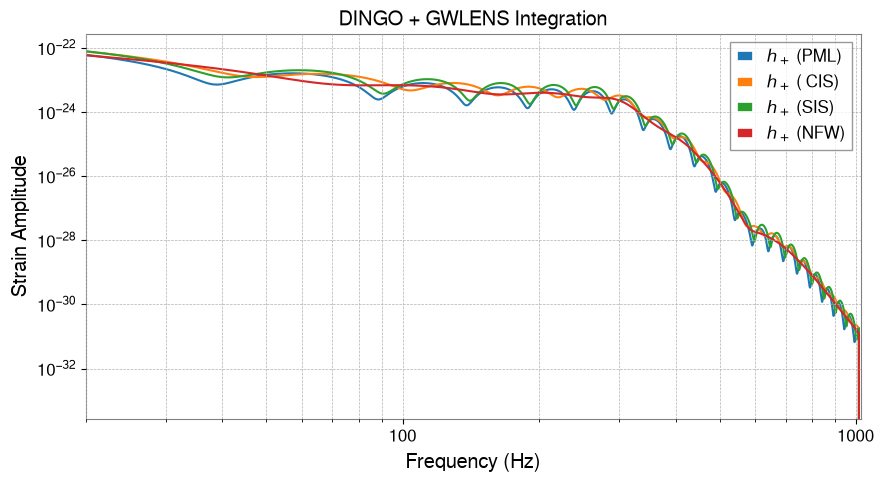

In [ ]:
%matplotlib inline
wfg_pm = LensedWaveformGenerator(domain=domain,approximant="IMRPhenomXPHM",f_ref=20.0,lens_model_code="gwlens",amplification_factor_function="gwlens_point")
wfg_cis = LensedWaveformGenerator(domain=domain,approximant="IMRPhenomXPHM",f_ref=20.0,lens_model_code="gwlens",amplification_factor_function="gwlens_cis")
wfg_sis = LensedWaveformGenerator(domain=domain,approximant="IMRPhenomXPHM",f_ref=20.0,lens_model_code="gwlens",amplification_factor_function="gwlens_sis")
wfg_nfw = LensedWaveformGenerator(domain=domain,approximant="IMRPhenomXPHM",f_ref=20.0,lens_model_code="gwlens",amplification_factor_function="gwlens_nfw")

polarizations_pm = wfg_pm.generate_hplus_hcross(parameters.copy())
polarizations_cis = wfg_cis.generate_hplus_hcross(parameters.copy())
polarizations_sis = wfg_sis.generate_hplus_hcross(parameters.copy())
polarizations_nfw = wfg_nfw.generate_hplus_hcross(parameters.copy())

freqs = domain.sample_frequencies

h_plus_pm = polarizations_pm["h_plus"]
h_plus_cis = polarizations_cis["h_plus"]
h_plus_sis = polarizations_sis["h_plus"]
h_plus_nfw = polarizations_nfw["h_plus"]

h_cross_pm = polarizations_pm["h_cross"]
h_cross_cis = polarizations_cis["h_cross"]
h_cross_sis = polarizations_sis["h_cross"]
h_cross_nfw = polarizations_nfw["h_cross"]


plt.figure(figsize=(10, 5))
plt.loglog(freqs, np.abs(h_plus_pm),label="$h_+$ (PML)")
plt.loglog(freqs, np.abs(h_plus_cis),label="$h_+$ ( CIS)")
plt.loglog(freqs, np.abs(h_plus_sis),label="$h_+$ (SIS)")
plt.loglog(freqs, np.abs(h_plus_nfw),label="$h_+$ (NFW)")




plt.xlabel("Frequency (Hz)")
plt.ylabel("Strain Amplitude")
plt.xlim(20, 1024)
plt.legend()
plt.title("DINGO + GWLENS Integration")
plt.grid(True, which="both", ls="--")
#plt.show()
# plt.savefig('test.pdf',dpi=300)
